# Random forest experiments

**Goal:** see whether a random forest can beat the majority-class baseline that AdaBoost could not
(`ada_boost.ipynb`), and which settings matter.

**Why random forest:** bagged deep trees with random feature subsets have lower variance than
boosting and are much less sensitive to noisy labels. With 670 redundant features, the per-split
feature sampling (`max_features`) also stops a few subject-specific features from dominating every
tree. Out-of-the-box probabilities let us tune a decision threshold for class 0.

**Carried over from AdaBoost:** subjects E and J are only in the test set, so we choose settings using
**GroupKFold by subject**, leave `subject` out as a feature, and test the top idea from that notebook:
**per-subject normalisation**.

Lab-notebook format: **hypothesis → code → result → interpretation** for each experiment.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_validate, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

## 1. Load data

In [2]:
train = pd.read_csv("train_data.csv")
test = pd.read_csv("test_data.csv")
sample_solution = pd.read_csv("sample_solution.csv")

print("Train shape:", train.shape)
print("Test shape :", test.shape)
train.output.value_counts(normalize=True)

Train shape: (4584, 670)
Test shape : (1732, 669)


output
1    0.844895
0    0.155105
Name: proportion, dtype: float64

## 2. Preprocessing: raw and per-subject normalised features

Same raw preprocessing as the AdaBoost notebook: one-hot `state`, drop `subject` and constant columns.

The second version z-scores every numeric sensor column (`x*`, `y*`, `z*`) **within each subject**,
so the model sees each reading relative to that subject's own baseline. The mean and std come from
all of a subject's rows in train and test together. That uses no labels, and it is the only way to
normalise subjects E and J, which have no training rows.

In [3]:
target = "output"
groups = train["subject"]
y = train[target]

def prep(df):
    X = df.drop(columns=[c for c in ["output", "subject"] if c in df])
    return pd.get_dummies(X, columns=["state"], dtype=int)

X_raw = prep(train)
X_test_raw = prep(test).reindex(columns=X_raw.columns, fill_value=0)
const_cols = X_raw.columns[X_raw.nunique() <= 1]
X_raw = X_raw.drop(columns=const_cols)
X_test_raw = X_test_raw.drop(columns=const_cols)

sensor_cols = [c for c in X_raw.columns if c[0] in "xyz" and c[1:].isdigit()]

def subject_zscore(X_tr, X_te):
    both = pd.concat([X_tr.assign(_s=train.subject.values), X_te.assign(_s=test.subject.values)])
    g = both.groupby("_s")[sensor_cols]
    z = (both[sensor_cols] - g.transform("mean")) / g.transform("std").replace(0, np.nan)
    both[sensor_cols] = z.fillna(0)
    both = both.drop(columns="_s")
    return both.iloc[:len(X_tr)].reset_index(drop=True), both.iloc[len(X_tr):].reset_index(drop=True)

X_norm, X_test_norm = subject_zscore(X_raw, X_test_raw)
print(f"{X_raw.shape[1]} features, {len(sensor_cols)} of them normalised per subject")

564 features, 558 of them normalised per subject


/var/folders/hr/56tdh60x4712fhss1_h0nrsc0000gn/T/ipykernel_20336/61901007.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  both = pd.concat([X_tr.assign(_s=train.subject.values), X_te.assign(_s=test.subject.values)])


## 3. Evaluation harness and majority-class baseline

Same harness as AdaBoost: accuracy (the competition metric) and macro-F1, under both stratified
5-fold (optimistic) and GroupKFold by subject (closer to the test set).

In [4]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gkf = GroupKFold(n_splits=5)
results = []

def evaluate(name, model, X):
    row = {"model": name}
    for cv_name, cv, kw in [("strat", skf, {}), ("group", gkf, {"groups": groups})]:
        s = cross_validate(model, X, y, cv=cv, n_jobs=-1,
                           scoring=["accuracy", "f1_macro"], **kw)
        row[f"{cv_name}_acc"] = s["test_accuracy"].mean()
        row[f"{cv_name}_acc_std"] = s["test_accuracy"].std()
        row[f"{cv_name}_f1m"] = s["test_f1_macro"].mean()
    results.append(row)
    return pd.Series(row)

evaluate("majority baseline", DummyClassifier(strategy="most_frequent"), X_raw)

model            majority baseline
strat_acc                 0.844895
strat_acc_std             0.000424
strat_f1m                 0.457964
group_acc                 0.852051
group_acc_std               0.1156
group_f1m                  0.45784
dtype: object

## 4. Experiment 1: default random forest on raw features

**Hypothesis:** a 300-tree forest will score well on stratified CV, because deep trees can memorise
subject-specific patterns, but it will be close to the baseline on grouped CV, like AdaBoost.

In [5]:
rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE)
evaluate("rf default, raw", rf, X_raw)

model            rf default, raw
strat_acc               0.853403
strat_acc_std           0.002566
strat_f1m               0.526932
group_acc               0.848169
group_acc_std           0.119565
group_f1m               0.461232
dtype: object

**Interpretation:** the hypothesis held. Stratified CV goes up a little (0.853 vs 0.845, macro-F1
0.53), but grouped CV falls below the baseline (0.848 vs 0.852). The forest is learning patterns that
belong to the subjects it has already seen.

## 5. Experiment 2: per-subject normalisation

**Hypothesis:** if the raw features mostly encode *who* the subject is, z-scoring within subject
removes that and leaves the within-subject changes that relate to the class. Grouped accuracy should
rise above the baseline, and the gap between stratified and grouped CV should shrink.

In [6]:
evaluate("rf default, subject-norm", rf, X_norm)
pd.DataFrame(results).set_index("model").round(4)

,strat_acc,strat_acc_std,strat_f1m,group_acc,group_acc_std,group_f1m
model,,,,,,
majority baseline,0.8449,0.0004,0.4580,0.8521,0.1156,0.4578
"rf default, raw",0.8534,0.0026,0.5269,0.8482,0.1196,0.4612
"rf default, subject-norm",0.8661,0.0074,0.6631,0.8433,0.1163,0.4649


**Interpretation:** this was half right, and the half that failed matters. Per-subject normalisation
gives the **best stratified result so far** (0.866 acc, macro-F1 0.66, up from 0.53). So within a
subject there *is* class-0 signal once each subject's baseline is removed. But grouped accuracy
*drops* to 0.843. Whatever separates the classes inside one subject doesn't carry over to new
subjects. Because grouped CV is our selection metric, the rest of the notebook uses the **raw**
features.

## 6. Experiment 3: tune `max_features` and `min_samples_leaf`

**Hypothesis:** with hundreds of redundant features, `max_features` matters most. Fewer features per
split means less correlated trees. Larger leaves smooth the probability estimates and should help on
unseen subjects. We tune on grouped CV using the better feature set from Experiment 2.

In [7]:
best_rep = max(["raw", "subject-norm"],
               key=lambda r: pd.DataFrame(results).set_index("model").loc[f"rf default, {r}", "group_acc"])
X_best, X_test_best = (X_norm, X_test_norm) if best_rep == "subject-norm" else (X_raw, X_test_raw)
print("Using features:", best_rep)

grid = []
for mf in ["sqrt", 0.1, 0.3]:
    for leaf in [1, 5, 20]:
        m = RandomForestClassifier(n_estimators=300, max_features=mf, min_samples_leaf=leaf,
                                   n_jobs=-1, random_state=RANDOM_STATE)
        s = cross_validate(m, X_best, y, cv=gkf, groups=groups, n_jobs=-1, scoring=["accuracy", "f1_macro"])
        grid.append({"max_features": mf, "min_samples_leaf": leaf,
                     "group_acc": s["test_accuracy"].mean(), "group_f1m": s["test_f1_macro"].mean()})
grid = pd.DataFrame(grid)
grid.pivot(index="max_features", columns="min_samples_leaf", values="group_acc").round(4)

Using features: raw


min_samples_leaf,1,5,20
max_features,,,
0.1,0.8473,0.8476,0.8508
0.3,0.8453,0.8476,0.8493
sqrt,0.8482,0.8498,0.8514


In [8]:
best = grid.loc[grid.group_acc.idxmax()]
best_params = {"max_features": best.max_features, "min_samples_leaf": int(best.min_samples_leaf)}
print("Best:", best_params)
rf_best = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE, **best_params)
rf_row = evaluate(f"rf tuned {best_params}, {best_rep}", rf_best, X_best)
rf_row

Best: {'max_features': 'sqrt', 'min_samples_leaf': 20}


model            rf tuned {'max_features': 'sqrt', 'min_samples...
strat_acc                                                 0.847295
strat_acc_std                                             0.000744
strat_f1m                                                 0.484187
group_acc                                                 0.851591
group_acc_std                                             0.115526
group_f1m                                                 0.461263
dtype: object

**Interpretation:** every setting falls in 0.845–0.851, inside the baseline's noise (std is about
0.12 across folds). The best setting, `sqrt` with leaf 20, is the most regularised one. It scores
0.8516 vs 0.8521 because big leaves push almost every prediction to class 1. Stratified F1 falls from
0.53 to 0.48 for the same reason. Tuning just moves the forest closer to predicting the majority
class.

## 7. Experiment 4: extremely randomised trees

**Hypothesis:** Extra Trees picks split thresholds at random, which adds more variance reduction than
a random forest. If the remaining errors come from overfitting individual subjects, Extra Trees should
do slightly better on grouped CV.

In [9]:
et = ExtraTreesClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE, **best_params)
et_row = evaluate(f"extra trees {best_params}, {best_rep}", et, X_best)
pd.DataFrame(results).set_index("model").round(4)

,strat_acc,strat_acc_std,strat_f1m,group_acc,group_acc_std,group_f1m
model,,,,,,
majority baseline,0.8449,0.0004,0.4580,0.8521,0.1156,0.4578
"rf default, raw",0.8534,0.0026,0.5269,0.8482,0.1196,0.4612
"rf default, subject-norm",0.8661,0.0074,0.6631,0.8433,0.1163,0.4649
"rf tuned {'max_features': 'sqrt', 'min_samples_leaf': 20}, raw",0.8473,0.0007,0.4842,0.8516,0.1155,0.4613
"extra trees {'max_features': 'sqrt', 'min_samples_leaf': 20}, raw",0.8453,0.0008,0.4609,0.8518,0.1157,0.4578


**Interpretation:** Extra Trees is the same story: 0.8518 grouped and macro-F1 0.458, exactly the
baseline's F1. It predicts class 1 almost everywhere. Neither random forest nor Extra Trees
improves on the baseline.

## 8. Experiment 5: decision threshold for class 0

**Hypothesis:** at the default 0.5 threshold the forest under-predicts the 15% minority class. Using
out-of-fold grouped probabilities, a higher threshold for predicting class 1 should trade a few false
0s for more true 0s and raise accuracy.

Model: ExtraTreesClassifier


acc at 0.5 = 0.8447, best = 0.8449 at t = 0.30


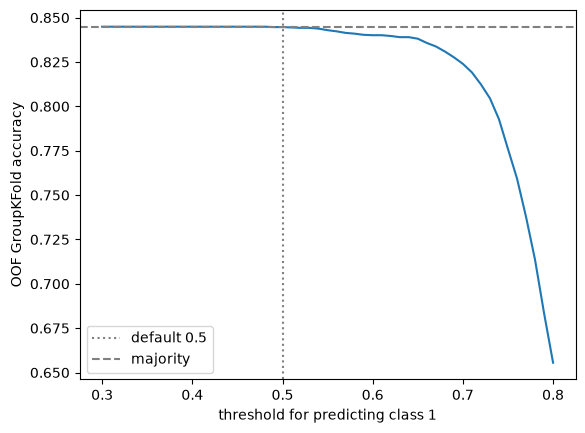

In [10]:
final_model = et if et_row.group_acc > rf_row.group_acc else rf_best
print("Model:", type(final_model).__name__)

oof = cross_val_predict(final_model, X_best, y, cv=gkf, groups=groups, method="predict_proba", n_jobs=-1)[:, 1]
thresholds = np.linspace(0.3, 0.8, 51)
accs = [accuracy_score(y, (oof >= t).astype(int)) for t in thresholds]
best_t = thresholds[int(np.argmax(accs))]

plt.plot(thresholds, accs)
plt.axvline(0.5, color="grey", ls=":", label="default 0.5")
plt.axhline((y == 1).mean(), color="grey", ls="--", label="majority")
plt.xlabel("threshold for predicting class 1")
plt.ylabel("OOF GroupKFold accuracy")
plt.legend()
print(f"acc at 0.5 = {accuracy_score(y, (oof >= 0.5).astype(int)):.4f}, "
      f"best = {max(accs):.4f} at t = {best_t:.2f}")

**Interpretation:** the hypothesis was wrong. Raising the threshold only adds errors. The best
threshold is at the bottom of the range (0.30), which means predicting 1 for every row. The
out-of-fold probabilities don't rank class-0 rows above class-1 rows on unseen subjects, so moving
the cut-off can't help. (Pooled out-of-fold accuracy, 0.845, differs from the per-fold mean, 0.852,
only because the folds are different sizes.)

## 9. Errors on held-out subjects

**Hypothesis:** compared with AdaBoost's all-1s confusion matrix, the forest should now get some
class-0 rows right on unseen subjects.

OOF grouped accuracy=0.8449  macro-F1=0.4580


,A,B,C,D,F,G,H,I,K,L,M
acc,0.971,0.86,0.756,0.938,0.779,0.492,0.862,0.962,1.0,0.912,0.709
frac_0,0.029,0.14,0.244,0.062,0.221,0.508,0.138,0.038,0.0,0.088,0.291


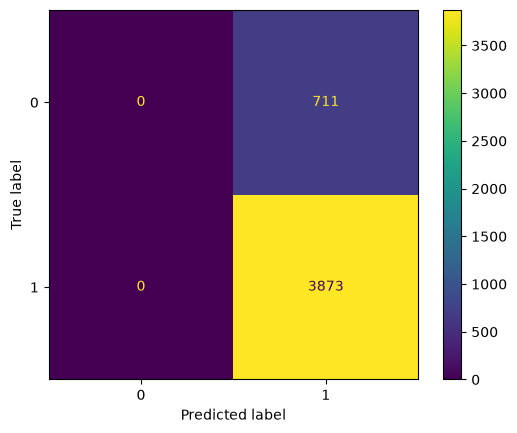

In [11]:
pred = (oof >= best_t).astype(int)
print(f"OOF grouped accuracy={accuracy_score(y, pred):.4f}  macro-F1={f1_score(y, pred, average='macro'):.4f}")
ConfusionMatrixDisplay(confusion_matrix(y, pred)).plot()
pd.DataFrame({"acc": pd.Series(pred == y).groupby(groups.values).mean(),
              "frac_0": (y == 0).groupby(groups.values).mean()}).round(3).T

**Interpretation:** macro-F1 is 0.458, the same as the baseline, so the model predicts 1 for every
row, just as AdaBoost did. Per-subject accuracy is therefore just 1 minus each subject's class-0 rate
(G: 0.49, M: 0.71, K: 1.0). That class-0 rate is the only thing driving the grouped score, and
nothing in these features predicts it for a subject the model hasn't seen.

## 10. Feature importance

The grade includes 10% for explainability. As in the AdaBoost notebook we compare:
- **Impurity importance** (`feature_importances_`): averaged over all trees, biased toward
  high-cardinality features.
- **Permutation importance** on held-out subjects: the accuracy drop when a feature is shuffled.

**Hypothesis:** if per-subject normalisation removed subject identity, the two views should now agree
more than they did for AdaBoost.

Held-out subjects: ['C', 'I']


Top-20 overlap: []


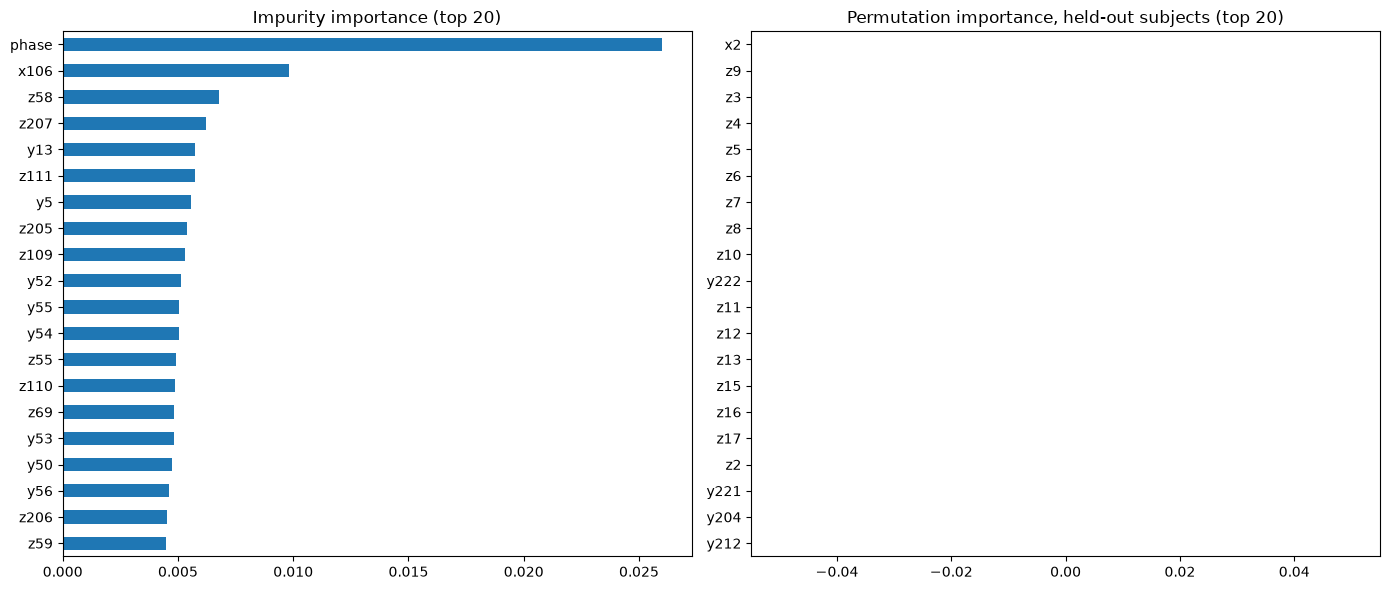

In [12]:
tr_idx, va_idx = next(GroupKFold(n_splits=4).split(X_best, y, groups))
print("Held-out subjects:", sorted(groups.iloc[va_idx].unique()))
final_model.fit(X_best.iloc[tr_idx], y.iloc[tr_idx])

imp = pd.Series(final_model.feature_importances_, index=X_best.columns).sort_values(ascending=False)
perm = permutation_importance(final_model, X_best.iloc[va_idx], y.iloc[va_idx],
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_best.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
imp.head(20)[::-1].plot.barh(ax=axes[0], title="Impurity importance (top 20)")
perm_imp.head(20)[::-1].plot.barh(ax=axes[1], title="Permutation importance, held-out subjects (top 20)")
plt.tight_layout()
print("Top-20 overlap:", sorted(set(imp.head(20).index) & set(perm_imp.head(20).index)))

**Interpretation:** none of the top 20 features by impurity are in the top 20 by permutation. The
features the trees split on most don't affect accuracy on held-out subjects (C, I), which supports
what the AdaBoost notebook found: the strong features identify subjects, not classes.

## 11. Fit on all training data and write a submission

In [13]:
final_model.fit(X_best, y)
submission = sample_solution.copy()
submission["output"] = (final_model.predict_proba(X_test_best)[:, 1] >= best_t).astype(int)
submission.to_csv("submission_random_forest.csv", index=False)
print(submission.output.value_counts(normalize=True))

output
1    1.0
Name: proportion, dtype: float64


## 12. Experiment 6: hybrid model (known subjects vs unseen subjects)

Section 5 showed that per-subject normalisation finds class-0 signal *within* subjects it has seen
(stratified macro-F1 0.66), and nothing so far transfers to unseen subjects. The test set mixes both
kinds, so we treat them separately:
- **Rows from subjects A–M** (also in training): use the per-subject normalised forest.
- **Rows from E and J** (test only): predict 1, which is the best option found so far for unseen
  subjects.

First we check that stratified CV is a fair way to score the known-subject rows. That is only true if
those test rows look like a random sample of each subject's data, not a separate later session.

In [14]:
known = test.subject.isin(train.subject.unique()).values
test_known = test[known]
print(f"Test rows from known subjects: {known.mean():.1%} ({known.sum()} rows)")
pd.concat({
    "train": train.phase.value_counts(normalize=True),
    "test, known subjects": test_known.phase.value_counts(normalize=True),
}, axis=1).sort_index().round(3)

Test rows from known subjects: 45.7% (791 rows)


,train,"test, known subjects"
phase,,
1,0.265,0.248
2,0.232,0.220
3,0.221,0.225
4,0.282,0.307


**Interpretation:** the `phase` mix (and the `state` mix) of known-subject test rows matches
training to within about 2 points. Those rows look like a random sample of the same recordings, so
stratified CV is a reasonable estimate for this part of the test set.

**Hypothesis:** for known subjects, (a) the subject-normalised forest beats predicting all 1s, and
(b) adding the subject itself as a feature (one-hot) helps further. Class-0 rates range from 0% (K)
to 51% (G), and for known subjects that rate can be learned.

We tune the threshold on stratified out-of-fold probabilities. We also report accuracy re-weighted to
the **test** mix of known subjects (I and G make up a large share of it), which is a better guess at
the leaderboard score for these rows. The threshold is chosen on the same out-of-fold predictions it
is scored on, so the numbers are slightly optimistic.

In [15]:
subj_cols = sorted(train.subject.unique())
def subject_onehot(df):
    return pd.get_dummies(df.subject, prefix="subj", dtype=int).reindex(
        columns=[f"subj_{s}" for s in subj_cols], fill_value=0).reset_index(drop=True)

candidates = {
    "subject-norm": (X_norm, X_test_norm),
    "subject-norm + subject id": (pd.concat([X_norm, subject_onehot(train)], axis=1),
                                  pd.concat([X_test_norm, subject_onehot(test)], axis=1)),
}
rf_known = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE)
oof_known = {name: cross_val_predict(rf_known, X, y, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]
             for name, (X, _) in candidates.items()}

test_mix = test_known.subject.value_counts(normalize=True)
def test_weighted_acc(pred):
    per_subj = pd.Series(pred == y.values).groupby(groups.values).mean()
    return (per_subj.reindex(test_mix.index) * test_mix).sum()

rows, known_thresholds = [], {}
for name, p in [("all 1s", np.ones(len(y)))] + list(oof_known.items()):
    t = thresholds[int(np.argmax([accuracy_score(y, (p >= t).astype(int)) for t in thresholds]))]
    known_thresholds[name] = t
    pred = (p >= t).astype(int)
    rows.append({"model": name, "threshold": t, "strat_acc": accuracy_score(y, pred),
                 "f1_macro": f1_score(y, pred, average="macro"),
                 "test_weighted_acc": test_weighted_acc(pred)})
known_results = pd.DataFrame(rows).set_index("model")
known_results.round(4)

,threshold,strat_acc,f1_macro,test_weighted_acc
model,,,,
all 1s,0.30,0.8449,0.4580,0.8426
subject-norm,0.55,0.8674,0.6955,0.8644
subject-norm + subject id,0.58,0.8695,0.7212,0.8666


Best for known subjects: subject-norm + subject id (threshold 0.58)


,A,B,C,D,F,G,H,I,K,L,M
acc,0.971,0.883,0.748,0.938,0.791,0.635,0.862,0.962,0.996,0.941,0.758
all_1s_acc,0.971,0.860,0.756,0.938,0.779,0.492,0.862,0.962,1.000,0.912,0.709
test_share,0.075,0.099,0.090,0.105,0.076,0.111,0.042,0.157,0.087,0.090,0.070


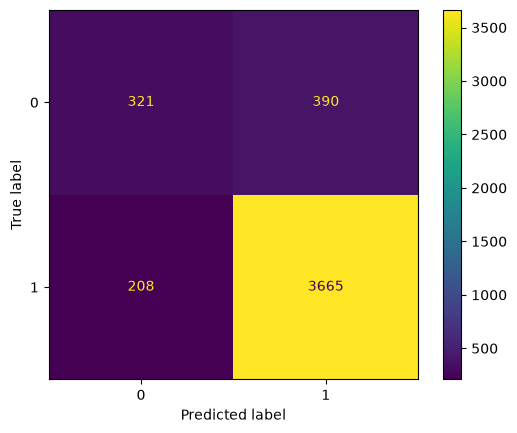

In [16]:
best_known = known_results.drop("all 1s").test_weighted_acc.idxmax()
t_known = known_thresholds[best_known]
pred = (oof_known[best_known] >= t_known).astype(int)
print(f"Best for known subjects: {best_known} (threshold {t_known:.2f})")
ConfusionMatrixDisplay(confusion_matrix(y, pred)).plot()
pd.DataFrame({"acc": pd.Series(pred == y.values).groupby(groups.values).mean(),
              "all_1s_acc": (y == 1).groupby(groups.values).mean(),
              "test_share": test_mix}).round(3).T

**Interpretation:** both parts of the hypothesis held. For known subjects:
- The subject-normalised forest raises test-weighted accuracy from 0.843 (all 1s) to **0.864**.
  Adding the subject one-hot raises it to **0.867** (macro-F1 0.72, up from 0.46). This is the first
  model in either notebook that clearly beats predicting all 1s.
- Most of the gain comes from **G** (0.49 → 0.64), **M** (0.71 → 0.76), **L** and **B**, the
  subjects with the most class-0 rows. On subjects that are almost all class 1 (A, D, I, K) it still
  predicts 1, so nothing is lost there. Only C is slightly worse (0.756 → 0.748).
- The best threshold is 0.58, above 0.5, so the model needs only moderate confidence before it
  predicts class 0.

## 13. Hybrid submission

Fit the best known-subject model on all of the training data, predict the known-subject test rows
with its tuned threshold, and set every E and J row to 1.

In [17]:
X_fit, X_test_fit = candidates[best_known]
rf_known.fit(X_fit, y)
hybrid = sample_solution.copy()
hybrid["output"] = 1
hybrid.loc[known, "output"] = (rf_known.predict_proba(X_test_fit[known])[:, 1] >= t_known).astype(int)
hybrid.to_csv("submission_hybrid.csv", index=False)

print(f"Predicted class 0: {(hybrid.output == 0).mean():.1%} of all test rows, "
      f"{(hybrid.output[known] == 0).mean():.1%} of known-subject rows")
(hybrid.output[known] == 0).groupby(test_known.subject.values).mean().round(3).rename("pred_frac_0")

Predicted class 0: 5.1% of all test rows, 11.3% of known-subject rows


A    0.000
B    0.051
C    0.042
D    0.000
F    0.133
G    0.739
H    0.030
I    0.000
K    0.000
L    0.028
M    0.109
Name: pred_frac_0, dtype: float64

**Interpretation:** the hybrid predicts class 0 for 11% of known-subject rows, below the 15%
training rate, and concentrates it in G (74%), F (13%) and M (11%). G's figure is higher than its
training class-0 rate (51%), so G is where this submission is most likely to be wrong.

**Expected leaderboard effect:** about +2.4 pts on the 46% of rows from known subjects, so about
**+1.1 pts overall** compared with the all-1s submissions. E and J are unchanged. This assumes the
known-subject test rows are sampled like the training rows (supported by the phase check) and is a
little optimistic, because the threshold was tuned on the same out-of-fold predictions it was
scored on.

## Summary and next steps

**Result:** none of the tree ensembles beat the majority baseline on GroupKFold. Best was Extra
Trees at 0.8518 vs 0.8521. Threshold tuning ends at predicting all 1s, so
`submission_random_forest.csv` is all 1s and will score about the same as the AdaBoost submission.

**What we learned (new compared with AdaBoost):**
- Per-subject normalisation **does** reveal class-0 signal *within* subjects (stratified macro-F1
  0.53 → 0.66). The signal is real, but it depends on the subject.
- It doesn't transfer to unseen subjects. Grouped accuracy is set mostly by each subject's class-0
  rate, which ranges from 0% to 51%.

**Hybrid (sections 12–13):** splitting the test set by subject works. For the 46% of test rows from
subjects seen in training, a per-subject normalised forest with subject one-hot features reaches
0.867 test-weighted CV accuracy vs 0.843 for all 1s. That is about +1.1 pts expected overall.
Submit **`submission_hybrid.csv`** rather than `submission_random_forest.csv`.

**Next steps, most promising first:**
1. Submit the hybrid and compare its public score with the AdaBoost all-1s score to check the
   +1.1 pt estimate.
2. Improve the known-subject model: gradient boosting on the same normalised features, or one model
   per high-variance subject (G, M, F, C).
3. Unseen subjects (E, J; 54% of test) are still all 1s. Check whether `phase` or `state` predicts
   class 0 consistently across subjects, or try features relative to each subject's phase-1 rows.

*Runtime note:* the whole notebook runs in about 10 minutes on an M-series Mac.